# Reviewer verification: saved Sleep-EDF outcomes

This notebook recounts approved saved confusion evidence, not EEG or model inference. The author approved inclusion of the cluster counts and frozen splits. Cluster aliases remain pseudonyms, not guaranteed anonymous identifiers. See docs/REVIEWER_VERIFICATION.md.

In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent] if (p / "release_tools/verify.py").is_file())
sys.path.insert(0, str(ROOT / "release_tools"))
from verify import verify


In [2]:
result = verify(ROOT, ROOT / "verification_outputs/notebook")
print(json.dumps(result, indent=2))

{
  "successful": true,
  "numeric_checks": 654,
  "models": 9,
  "target_epochs_per_checkpoint": 31156,
  "scope_requested": "auto",
  "subject_bootstrap_verified": true,
  "frozen_split_verified": true,
  "independent_subject_clusters": 12,
  "bootstrap_resamples": 10000,
  "bootstrap_weights_sha256": "ea7c14aaf875b2726b506fa713cce9735097031942899ebed24875c23af4c356",
  "dataset_download_required": false,
  "pytorch_required": false,
  "training_called": false,
  "inference_called": false,
  "privacy_review_required": true,
  "coverage": [
    "accuracy",
    "five-class macro-F1",
    "all class precision/recall/F1",
    "balanced accuracy",
    "kappa",
    "count and normalized confusion matrices",
    "all fixed seeds and sample SD",
    "transition/stable outcomes",
    "paired subject-bootstrap intervals",
    "frozen split integrity"
  ],
  "unavailable": [
    "ROC/PR/AP/Brier/ECE require approved probabilities",
    "EEG/hypnograms/embeddings/saliency/attention require exclu

All predefined seeds are retained. Seed SD is separate from subject uncertainty. Context/capacity/replication differ across M1 and M5/M7. Higher aggregate performance coexists with lower transition-target macro-F1; no causal mechanism is established.

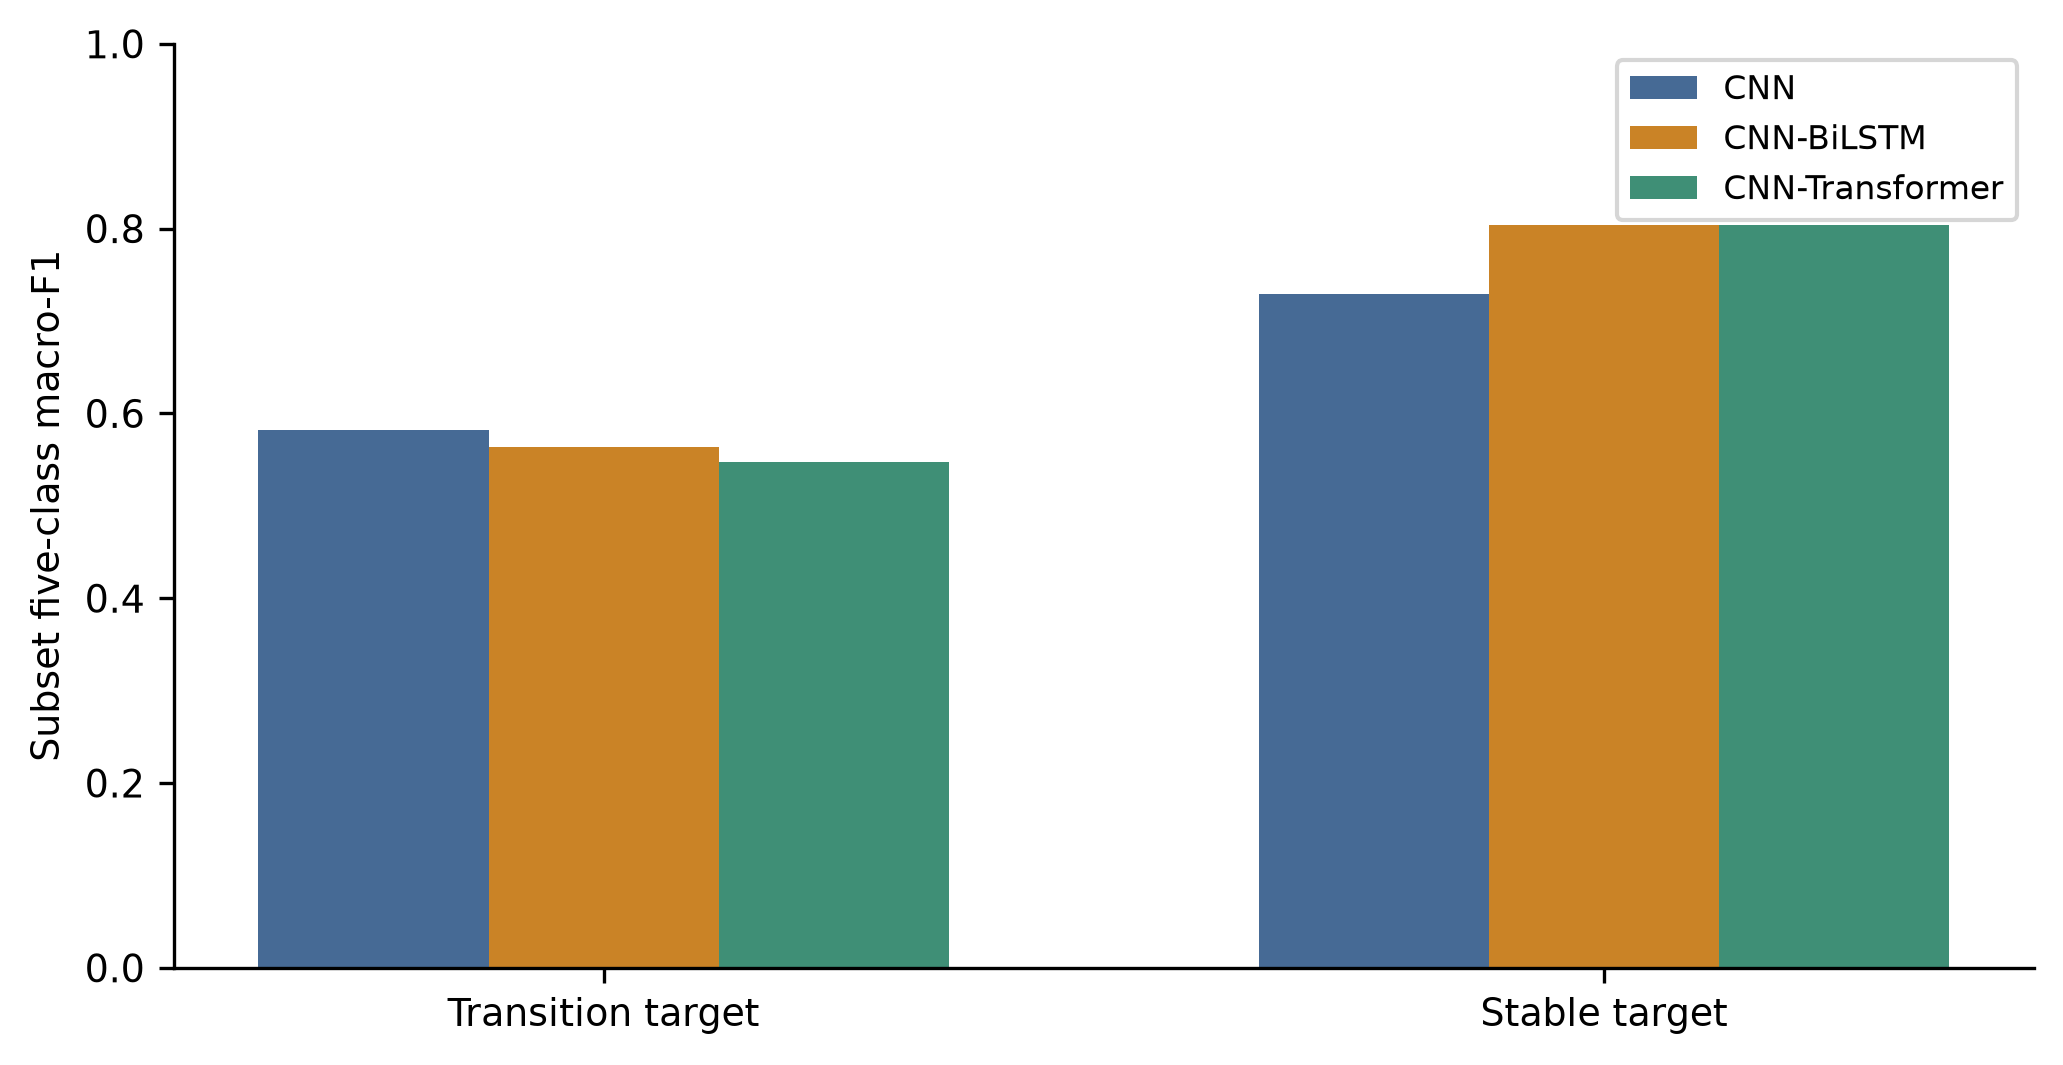

| model | seeds | parameters | accuracy | macro_F1 | N1_F1 | subject_95_CI |
| --- | --- | --- | --- | --- | --- | --- |
| CNN | 1 | 40501 | 0.8018 | 0.7198 (single seed) | 0.3823 | [0.6853, 0.7477] |
| CNN-BiLSTM | 3 | 65717 | 0.8471 | 0.7771 ± 0.0066 | 0.4611 | [0.7472, 0.8005] |
| CNN-Transformer | 3 | 107893 | 0.8448 | 0.7758 ± 0.0118 | 0.4752 | [0.7460, 0.7994] |

Macro-F1 ± sample SD across fixed training seeds; the interval column is separately computed paired-subject uncertainty conditional on those seeds. Scores are ratios0–1.



In [3]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / "results/publication_figures/16_transition_errors.png")))
print((ROOT / "results/publication_tables/03a_primary_display.md").read_text())

The original test cohort is consumed. This notebook does not select a seed/model, fit a threshold, recalculate feature projections or perform training. Probability-based and physiological analyses require separately approved additional inputs.